# Introduction to Deep Learning, HSE Faculty of Computer Science

## Homework 1. Fully connected neural networks.

### General information

The grade after the penalty for submitting after the soft deadline is computed as $M_{\text{penalty}} = M_{\text{full}} \cdot 0.85^{t/1440}$, where $M_{\text{full}}$ is the full grade without the penalty and $t$ is the time in minutes since the soft deadline (rounded to two decimal places). So one day after the soft deadline you cannot get more than 8.5, and if you submit four days after the soft deadline, your maximum is 5.22 points.

### Grading and penalties

The maximum grade for the assignment is 10 points. Submissions after the deadline are not accepted.

The assignment must be done independently. "Similar" solutions are considered plagiarism, and all students involved (including those who were copied from) receive 0 points. If you found a solution to any of the tasks (or part of it) in an open source, you must link to that source in a separate block at the end of your work (you are most likely not the only one who found it, so a link is needed to avoid suspicion of plagiarism).

An inefficient implementation may lower your grade. The grade may also be reduced for poorly readable code and poorly formatted plots. All answers must be accompanied by code or comments explaining how they were obtained.

### About the assignment

In this assignment you will train a fully connected neural network to predict the release year of a song from its audio features. We will use the [Million Songs Dataset](https://samyzaf.com/ML/song_year/song_year.html).

In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from tqdm.notebook import tqdm
from IPython.display import clear_output

plt.rcParams.update({'font.size': 16})
sns.set_style('whitegrid')
np.random.seed(0xFA1AFE1)

Let's start by downloading and loading the data:

In [ ]:
#!wget -O data.txt.zip https://archive.ics.uci.edu/ml/machine-learning-databases/00203/YearPredictionMSD.txt.zip

In [ ]:
df = pd.read_csv('data.txt.zip', header=None)
df

,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
0,2001,49.94357,21.47114,73.07750,8.74861,-17.40628,-13.09905,-25.01202,-12.23257,7.83089,...,13.01620,-54.40548,58.99367,15.37344,1.11144,-23.08793,68.40795,-1.82223,-27.46348,2.26327
1,2001,48.73215,18.42930,70.32679,12.94636,-10.32437,-24.83777,8.76630,-0.92019,18.76548,...,5.66812,-19.68073,33.04964,42.87836,-9.90378,-32.22788,70.49388,12.04941,58.43453,26.92061
2,2001,50.95714,31.85602,55.81851,13.41693,-6.57898,-18.54940,-3.27872,-2.35035,16.07017,...,3.03800,26.05866,-50.92779,10.93792,-0.07568,43.20130,-115.00698,-0.05859,39.67068,-0.66345
3,2001,48.24750,-1.89837,36.29772,2.58776,0.97170,-26.21683,5.05097,-10.34124,3.55005,...,34.57337,-171.70734,-16.96705,-46.67617,-12.51516,82.58061,-72.08993,9.90558,199.62971,18.85382
4,2001,50.97020,42.20998,67.09964,8.46791,-15.85279,-16.81409,-12.48207,-9.37636,12.63699,...,9.92661,-55.95724,64.92712,-17.72522,-1.49237,-7.50035,51.76631,7.88713,55.66926,28.74903
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515340,2006,51.28467,45.88068,22.19582,-5.53319,-3.61835,-16.36914,2.12652,5.18160,-8.66890,...,4.81440,-3.75991,-30.92584,26.33968,-5.03390,21.86037,-142.29410,3.42901,-41.14721,-15.46052
515341,2006,49.87870,37.93125,18.65987,-3.63581,-27.75665,-18.52988,7.76108,3.56109,-2.50351,...,32.38589,-32.75535,-61.05473,56.65182,15.29965,95.88193,-10.63242,12.96552,92.11633,10.88815
515342,2006,45.12852,12.65758,-38.72018,8.80882,-29.29985,-2.28706,-18.40424,-22.28726,-4.52429,...,-18.73598,-71.15954,-123.98443,121.26989,10.89629,34.62409,-248.61020,-6.07171,53.96319,-8.09364
515343,2006,44.16614,32.38368,-3.34971,-2.49165,-19.59278,-18.67098,8.78428,4.02039,-12.01230,...,67.16763,282.77624,-4.63677,144.00125,21.62652,-29.72432,71.47198,20.32240,14.83107,39.74909


Let's look at the data statistics.

In [ ]:
df.describe()

,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
count,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,...,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000,515345.000000
mean,1998.397082,43.387126,1.289554,8.658347,1.164124,-6.553601,-9.521975,-2.391089,-1.793236,3.727876,...,15.755406,-73.461500,41.542422,37.934119,0.315751,17.669213,-26.315336,4.458641,20.035136,1.329105
std,10.931046,6.067558,51.580351,35.268585,16.322790,22.860785,12.857751,14.571873,7.963827,10.582861,...,32.099635,175.618889,122.228799,95.050631,16.161764,114.427905,173.977336,13.346557,185.558247,22.088576
min,1922.000000,1.749000,-337.092500,-301.005060,-154.183580,-181.953370,-81.794290,-188.214000,-72.503850,-126.479040,...,-437.722030,-4402.376440,-1810.689190,-3098.350310,-341.789120,-3168.924570,-4319.992320,-236.039260,-7458.378150,-381.424430
25%,1994.000000,39.954690,-26.059520,-11.462710,-8.487500,-20.666450,-18.440990,-10.780600,-6.468420,-2.293660,...,-1.812650,-139.555160,-20.986900,-4.669540,-6.781590,-31.580610,-101.530300,-2.566090,-59.509270,-8.820210
50%,2002.000000,44.258500,8.417850,10.476320,-0.652840,-6.007770,-11.188390,-2.046670,-1.736450,3.822310,...,9.171850,-53.090060,28.791060,33.623630,0.820840,15.598470,-21.204120,3.117640,7.759730,0.053050
75%,2006.000000,47.833890,36.124010,29.764820,8.787540,7.741870,-2.388960,6.508580,2.913450,9.961820,...,26.274480,13.478730,89.661770,77.785800,8.470990,67.794960,52.389330,9.967740,86.351610,9.679520
max,2011.000000,61.970140,384.065730,322.851430,335.771820,262.068870,166.236890,172.402680,126.741270,146.297950,...,840.973380,4469.454870,3210.701700,1734.079690,260.544900,3662.065650,2833.608950,463.419500,7393.398440,677.899630


The target variable, the song's release year, is in the first column. Let's look at its distribution.

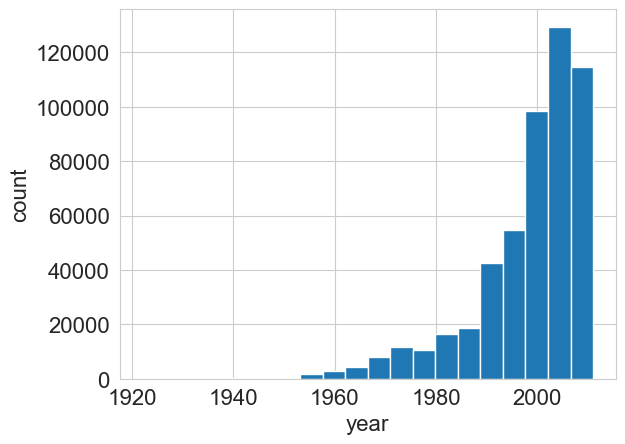

Range: 1922 - 2011
Unique values: 89


In [ ]:
plt.hist(df.iloc[:, 0], bins=20)
plt.xlabel('year')
plt.ylabel('count')
plt.show()
print(f'Range: {df.iloc[:, 0].min()} - {df.iloc[:, 0].max()}')
print(f'Unique values: {np.unique(df.iloc[:, 0]).size}')

Split the data into training and test sets (do not change anything here, so that everyone has the same split).

In [ ]:
X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

train_size = int(0.75 * X.shape[0])
X_train = X[:train_size, :]
y_train = y[:train_size]
X_test = X[train_size:, :]
y_test = y[train_size:]
X_train.shape, X_test.shape

((386508, 90), (128837, 90))

**Task 0 (0 points, but if it is not done, the maximum grade for the whole assignment is 0 points).** We will use MSE as the quality metric. Before training neural networks, we need to check a few simple baselines so that we have something to compare more complex algorithms with. Train a `Ridge` regression from `sklearn`. Also compute the quality of the best constant prediction.

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# среднее значение по y_train
y_pred_const = np.full_like(y_test, y_train.mean(), dtype=np.float64)
# MSE для константного прогноза
mse_const = mean_squared_error(y_test, y_pred_const)
print(f"MSE для наилучшего константного прогноза: {mse_const:.2f}")

# инициализация и обучение модели
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)

# предсказания и MSE
y_pred_ridge = ridge.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
print(f"MSE Ridge-регрессии: {mse_ridge:.2f}")

MSE для наилучшего константного прогноза: 117.63
MSE Ridge-регрессии: 89.75


Now let's start experimenting with neural networks. First, split off a validation set:

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=0xE2E4)
X_train.shape, X_val.shape

((289881, 90), (96627, 90))

## Chapter I. Getting a neural network to work (5 points)

**Task 1.1 (0.5 points).** Fill in the gaps in the `train_and_validate` function. It will help us run experiments. You can also add support for training on a GPU to make the experiments faster. GPUs are available for free on **Google Colab** and **Kaggle**.

In [ ]:
def plot_losses(train_losses, train_metrics, val_losses, val_metrics):
    '''
    Plot losses and metrics while training
      - train_losses: sequence of train losses
      - train_metrics: sequence of train MSE values
      - val_losses: sequence of validation losses
      - val_metrics: sequence of validation MSE values
    '''
    clear_output()
    fig, axs = plt.subplots(1, 2, figsize=(15, 5))
    axs[0].plot(range(1, len(train_losses) + 1), train_losses, label='train')
    axs[0].plot(range(1, len(val_losses) + 1), val_losses, label='val')
    axs[1].plot(range(1, len(train_metrics) + 1), train_metrics, label='train')
    axs[1].plot(range(1, len(val_metrics) + 1), val_metrics, label='val')

    if max(train_losses) / min(train_losses) > 10:
        axs[0].set_yscale('log')

    if max(train_metrics) / min(train_metrics) > 10:
        axs[0].set_yscale('log')

    for ax in axs:
        ax.set_xlabel('epoch')
        ax.legend()

    axs[0].set_ylabel('loss')
    axs[1].set_ylabel('MSE')
    plt.show()


def train_and_validate(model, optimizer, criterion, metric, train_loader, val_loader,
                       num_epochs, verbose=True):
    '''
    Train and validate neural network
      - model: neural network to train
      - optimizer: optimizer chained to a model
      - criterion: loss function class
      - metric: function to measure MSE taking neural networks predictions
                 and ground truth labels
      - train_loader: DataLoader with train set
      - val_loader: DataLoader with validation set
      - num_epochs: number of epochs to train
      - verbose: whether to plot metrics during training
    Returns:
      - train_mse: training MSE over the last epoch
      - val_mse: validation MSE after the last epoch
    '''

    train_losses, val_losses = [], []
    train_metrics, val_metrics = [], []

    for epoch in range(1, num_epochs + 1):
        model.train()
        running_loss, running_metric = 0, 0
        pbar = tqdm(train_loader, desc=f'Training {epoch}/{num_epochs}') if verbose else train_loader

        for i, (X_batch, y_batch) in enumerate(pbar, 1):

            #
            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()
            #

            with torch.no_grad():
                metric_value = metric(predictions, y_batch)
                if isinstance(metric_value, torch.Tensor):
                    metric_value = metric_value.item()
                running_loss += loss.item() * X_batch.shape[0]
                running_metric += metric_value * X_batch.shape[0]

            if verbose and i % 100 == 0:
                pbar.set_postfix({'loss': loss.item(), 'MSE': metric_value})

        train_losses.append(running_loss / len(train_loader.dataset))
        train_metrics.append(running_metric / len(train_loader.dataset))

        model.eval()
        running_loss, running_metric = 0, 0
        pbar = tqdm(val_loader, desc=f'Validating {epoch}/{num_epochs}') if verbose else val_loader

        for i, (X_batch, y_batch) in enumerate(pbar, 1):

            with torch.no_grad():
                #
                predictions = model(X_batch)
                loss = criterion(predictions, y_batch)
                #

                metric_value = metric(predictions, y_batch)
                if isinstance(metric_value, torch.Tensor):
                    metric_value = metric_value.item()
                running_loss += loss.item() * X_batch.shape[0]
                running_metric += metric_value * X_batch.shape[0]

            if verbose and i % 100 == 0:
                pbar.set_postfix({'loss': loss.item(), 'MSE': metric_value})

        val_losses.append(running_loss / len(val_loader.dataset))
        val_metrics.append(running_metric / len(val_loader.dataset))

        if verbose:
            plot_losses(train_losses, train_metrics, val_losses, val_metrics)

    if verbose:
        print(f'Validation MSE: {val_metrics[-1]:.3f}')

    return train_metrics[-1], val_metrics[-1]

**Task 1.2 (0.75 points).** Let's try to train our first neural network. The target variable here is discrete — it is the song's release year. So we will train the network for classification with the [cross-entropy loss](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).

- For the architecture, use two linear layers with a ReLU activation between them and 128 hidden neurons.
- Use SGD with `lr=1e-2`.
- Use a mini-batch size of about 32–64; about 3–4 training epochs should be enough.
- You will probably need `torch.utils.data.TensorDataset`. When converting numpy arrays to torch tensors, use the `torch.float32` type.
- Also transform the target variable so that it takes values from $0$ to $C-1$, where $C$ is the number of classes (better pass the transformed value to the TensorDataset; we will still need the original one)
- As the `metric` parameter of `train_and_validate`, pass a lambda that computes the MSE between the network output and the target. For classification, the predicted class is the one with the highest probability (or, equivalently, the highest **logit**$^1$).

$^1$ A **logit** is the output of the last linear layer and can take any real value. Applying Softmax to the logits gives the class probability distribution.

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y_train_enc = encoder.fit_transform(y_train)
y_val_enc = encoder.transform(y_val)
y_test_enc = encoder.transform(y_test)
n_classes = len(encoder.classes_)

In [ ]:
y_train_enc, n_classes

(array([78, 73, 86, ..., 80, 54, 76], shape=(289881,)), 89)

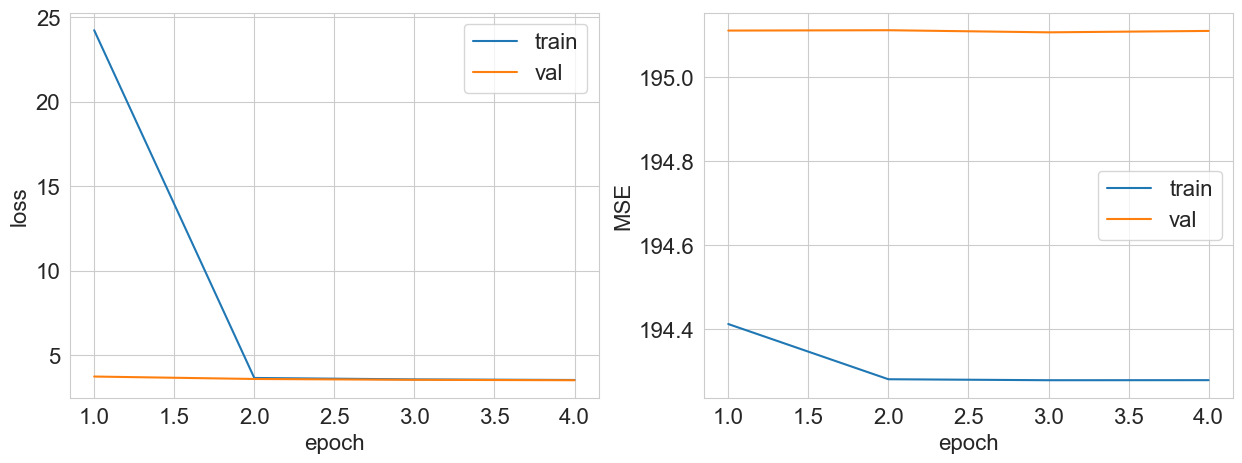

Validation MSE: 195.110


In [ ]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_enc, dtype=torch.long)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_enc, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64)
class cnn_classify(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

input_size = X.shape[1]
hidden_size = 128
output_size = n_classes

model = cnn_classify(input_size, hidden_size, output_size)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2)

def classification_mse(y_pred, y_true):
    pred_classes = y_pred.argmax(dim=1)
    mse = ((pred_classes - y_true) ** 2).float().mean()
    return mse

train_mse, val_mse = train_and_validate(model, optimizer, criterion,
                                        classification_mse, train_loader, val_loader, 4)


**Task 1.3 (0.5 points).** Comment on your observations. Did you manage to beat the baseline? Do you think it is a good idea to train a classifier for this task? Why?

**Answer:**
I did not manage to beat the baseline; training a classifier is a bad idea <br>
using classification loses information, because the target is actually numerical <br>
i.e. 1998 and 1999 are closer to each other than 1960 and 1999, but a classification model does not know that <br>

**Task 1.4 (0.75 points).** Now let's try to solve the task as regression. Train the neural network with [MSE](https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html).

- Use the same training hyperparameters.
- When passing the target to the TensorDataset, reshape it to (-1, 1).
- Do not forget to change the lambda you pass to `train_and_validate`.
- If something goes wrong, you can try smaller values of `lr`.

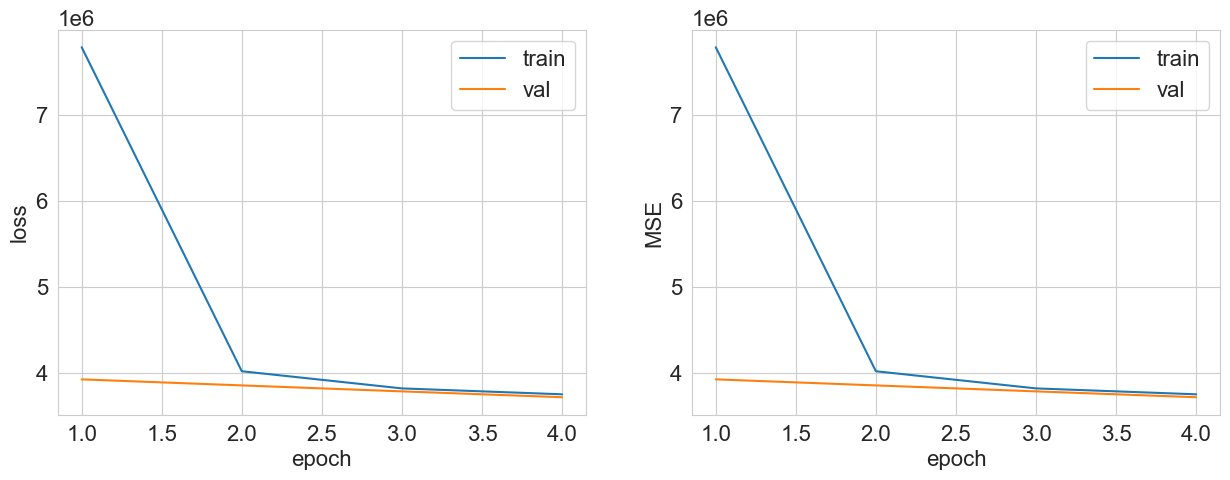

Validation MSE: 3717537.201
Train MSE: 3751400.896


In [ ]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

class cnn_regression(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, 1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

input_size = X_train.shape[1]
hidden_size = 128

model = cnn_regression(input_size, hidden_size)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-6)
criterion = nn.MSELoss()

def mse_metric_reg(predictions, true_values):
    return mean_squared_error(true_values.detach().numpy(), predictions.detach().numpy())

train_mse, val_mse = train_and_validate(model, optimizer, criterion, mse_metric_reg,
                                                train_loader, val_loader, 4)

print(f'Train MSE: {train_mse:.3f}')

**Task 1.5 (0.5 points).** Did you manage to stabilize training? Did smaller `lr` values help? Did switching from classification to regression make things better? Why do you think this happens? As a hint, look at the distribution of the target and the magnitude of the feature values.

**Answer:** it only worked with 1e-6; before that the program crashed with NaN <br>
smaller values only helped to stop the crashes; the MSE values are just terrible <br>
switching made things even worse — classification would have been better <br>
I think this happens because the data is messy and really needs to be normalized properly <br>

BUT in principle regression should give a better result, because the model learns a numerical target rather than categorical classes, so let's move on

**Task 1.6 (0.75 points).** Let's start by normalizing the target variable. Use min-max normalization so that the target takes values from 0 to 1. Implement the `normalize` and `denormalize` functions, which normalize the target and apply the inverse transformation, respectively. Estimate the minimum and maximum on the training set (i.e. these constants must be fixed and must not depend on the sample passed in).

In [ ]:
y_train_min = y_train.min()
y_train_max = y_train.max()
def normalize(sample):
    return (sample - y_train_min) / (y_train_max - y_train_min)

def denormalize(sample):
    return sample * (y_train_max - y_train_min) + y_train_min

Now repeat the experiment from **task 1.4**, training on the normalized target. Let's also make one more change: add a [sigmoid activation](https://pytorch.org/docs/stable/generated/torch.nn.Sigmoid.html) after the last linear layer of the network. This guarantees that the network predicts numbers in the interval $[0, 1]$. Using an activation is a fairly common trick when we want outputs in a specific range.

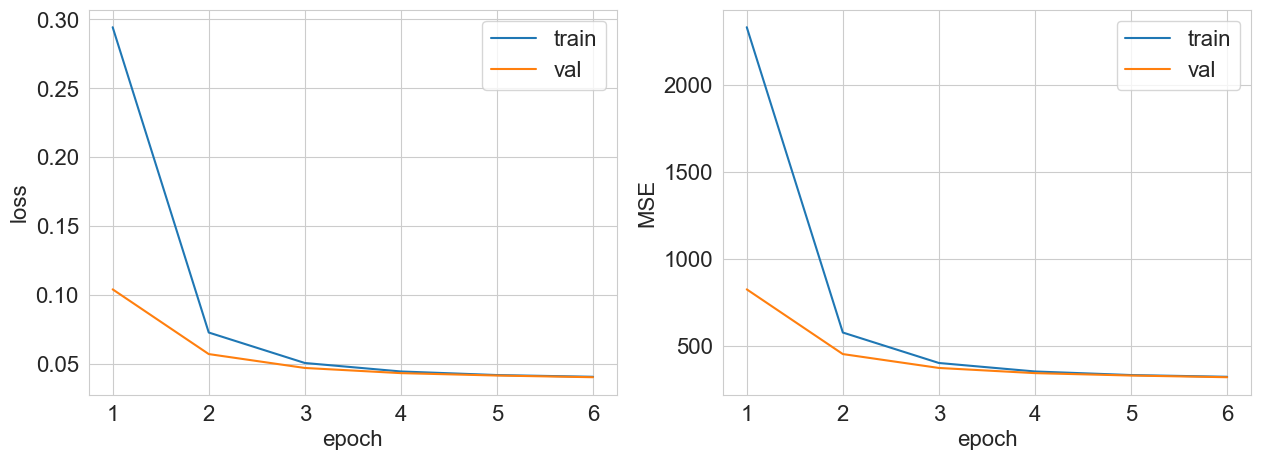

Validation MSE: 318.671
Train MSE: 321.198


In [ ]:
y_train_norm = normalize(y_train)
y_val_norm = normalize(y_val)

y_train_tensor = torch.tensor(y_train_norm, dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val_norm, dtype=torch.float32).reshape(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

class cnn_regression_normalized(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.sigmoid(x)
        return x

model = cnn_regression_normalized(input_size, hidden_size)

optimizer = torch.optim.SGD(model.parameters(), lr=1e-6)
criterion = nn.MSELoss()

def mse_metric_norm(predictions_normalized, true_values_normalized):
    predictions = denormalize(predictions_normalized.detach().numpy())
    true_values = denormalize(true_values_normalized.detach().numpy())
    return mean_squared_error(true_values, predictions)

train_mse, val_mse = train_and_validate(model, optimizer, criterion, mse_metric_norm,
                                                train_loader, val_loader, 6)

print(f'Train MSE: {train_mse:.3f}')

**Task 1.7 (0.5 points).** Compare the results of this experiment with the previous run.

**Answer:** before, it was a disaster like <br>
`Validation MSE: 3719713.993`
`Train MSE: 3753597.054` <br>
now it is MUCH better: <br>
`Validation MSE: 280.064`
`Train MSE: 279.298` <br>

**Task 1.8 (0.75 points).** This time let's normalize not only the target but also the input data fed to the network. For the inputs, use normalization by the mean and standard deviation. Transform the data and repeat the previous experiment. It probably makes sense to increase the number of training epochs.

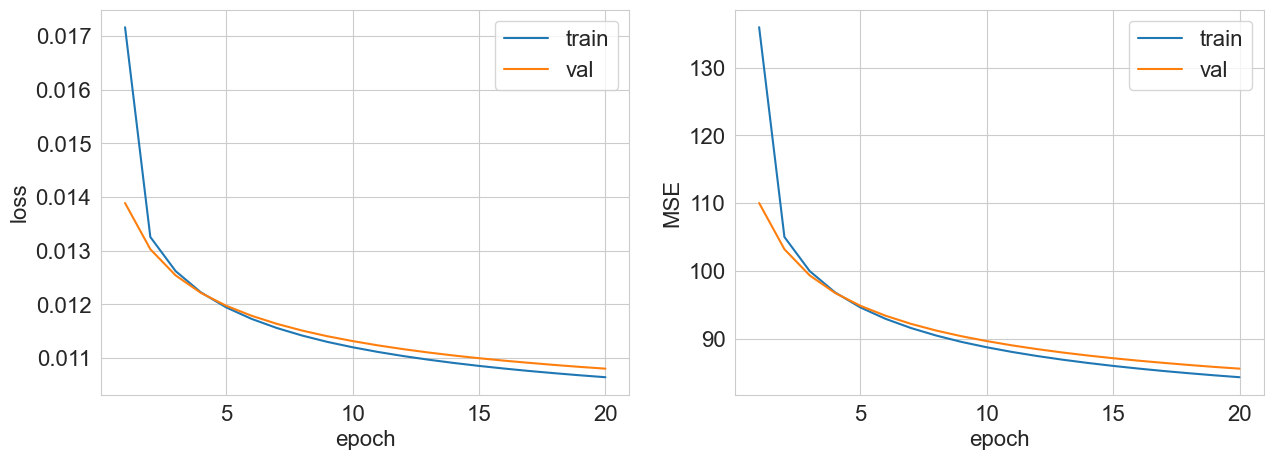

Validation MSE: 85.577
Train MSE: 84.312


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

model = cnn_regression_normalized(input_size, hidden_size)

optimizer = torch.optim.SGD(model.parameters(), lr=1e-2)
criterion = nn.MSELoss()

def mse_metric_scaled_norm(predictions_normalized, true_values_normalized):
    predictions = denormalize(predictions_normalized.detach().numpy())
    true_values = denormalize(true_values_normalized.detach().numpy())
    return mean_squared_error(true_values, predictions)

train_mse, val_mse = train_and_validate(
    model, optimizer, criterion,
    mse_metric_scaled_norm, train_loader, val_loader, 20
)

print(f'Train MSE: {train_mse:.3f}')

If you did everything correctly, you should get quality comparable to `Ridge` regression.

**Moral:** as you can see, we had to do a lot of tricky things just to make the neural network work as well as a simple linear model. This is, of course, an extreme case where the network simply does not learn without data normalization. In practice it is usually not that hard to get a neural network working out of the box, but making it work at full capacity is a much more laborious task. Writing training pipelines for neural models requires great care, and debugging often turns into guesswork. Fortunately, intuition often helps, and we hope you will develop it during the course. Let's start with two pieces of advice worth adopting:

- Always start any experiments with baselines: without them we would not have realized that the neural network was not learning at all.
- When setting up experiments, try to make as few changes as possible at a time (ideally one!): only then can you understand which changes affect the result.

## Part 2. Improving the neural network (5 points)

Let's keep experimenting with the neural network to achieve even better quality. In tasks 2.1–2.3, **run each experiment several times (4–5)** with the same training hyperparameters but different random initializations of the network (it is enough to run the code that initializes and trains the model in a loop: every constructor call initializes the model randomly). To compare the quality of different experiments, **draw box plots** over these runs.

Task 2.4 requires a hyperparameter search; there, run the experiment once for each value considered to save time.

**Task 2.1 (1 point).** Let's try other optimizers. Train the network with SGD+momentum and Adam. Describe your observations and use the best optimizer in later runs. For Adam a smaller learning rate is usually used, around $10^{-3}$.

In [ ]:
from sklearn.preprocessing import StandardScaler

# нормализуем
y_train_norm = normalize(y_train)
y_val_norm = normalize(y_val)
y_train_tensor = torch.tensor(y_train_norm, dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val_norm, dtype=torch.float32).reshape(-1, 1)

# скейлим
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)

# объединяем
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

# тест
X_test_scaled = scaler.transform(X_test)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_test_normaliszed = normalize(y_test)
y_test_tensor = torch.tensor(y_test_normaliszed, dtype=torch.float32)

In [ ]:
def custom_mse(predictions_normalized, true_values_normalized):
    predictions = denormalize(predictions_normalized.detach().numpy())
    true_values = denormalize(true_values_normalized.detach().numpy())
    return mean_squared_error(true_values, predictions)

def run_model(times, model, optim):
    train_mse_list = []
    val_mse_list = []
    test_mse_list = []
    for _ in range(times):
        if optim == 'sgdm':
            optimizer = torch.optim.SGD(model.parameters(), lr=1e-2, momentum=0.9)
        elif optim == 'adam':
            optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        else:
            print("Unknown, exiting...")
            return -1
        criterion = nn.MSELoss()
        metric = custom_mse
        train_mse, val_mse = train_and_validate(
            model, optimizer, criterion, metric,
            train_loader, val_loader,
            num_epochs=10, verbose=False
        )
        model.eval()
        with torch.no_grad():
            y_pred = model(X_test_tensor).view(-1, 1)
        test_mse = custom_mse(y_pred, y_test_tensor)
        print(f"Test MSE: {test_mse:.2f}")
        test_mse_list.append(test_mse)
        print(f"Validation MSE: {val_mse:.2f}")
        val_mse_list.append(val_mse)
        print(f"Trains MSE: {train_mse:.2f}")
        train_mse_list.append(train_mse)
    return train_mse_list, val_mse_list, test_mse_list

In [ ]:
class cnn_regression_normalized(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.sigmoid(x)
        return x
model = cnn_regression_normalized(input_size, hidden_size)

In [ ]:
input_size = X_train.shape[1]
hidden_size = 128
model = cnn_regression_normalized(input_size, hidden_size)
print("SGDM: ")
sgd_train_results, sgd_val_results, sgd_test_results = run_model(5, model, 'sgdm')
print("AdaM: ")
adam_train_results, adam_val_results, adam_test_results = run_model(5, model, 'adam')

SGDM: 
Test MSE: 78.63
Validation MSE: 80.46
Trains MSE: 78.56
Test MSE: 78.13
Validation MSE: 79.37
Trains MSE: 76.46
Test MSE: 77.83
Validation MSE: 78.95
Trains MSE: 75.12
Test MSE: 77.94
Validation MSE: 78.72
Trains MSE: 74.04
Test MSE: 78.16
Validation MSE: 78.52
Trains MSE: 73.16
AdaM: 
Test MSE: 78.08
Validation MSE: 77.83
Trains MSE: 72.99
Test MSE: 78.53
Validation MSE: 77.60
Trains MSE: 70.36
Test MSE: 79.84
Validation MSE: 78.51
Trains MSE: 68.94
Test MSE: 80.79
Validation MSE: 79.30
Trains MSE: 68.20
Test MSE: 81.49
Validation MSE: 79.44
Trains MSE: 67.48


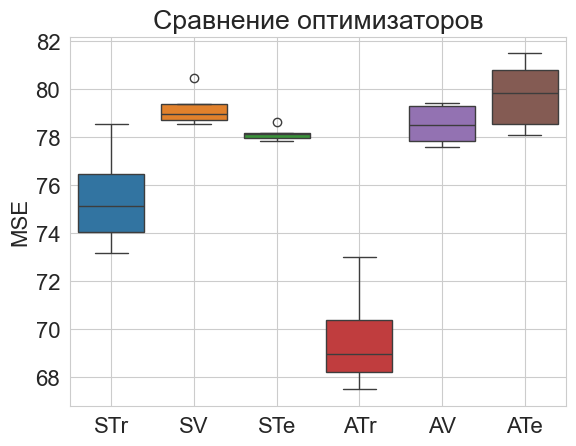

In [ ]:
results_df = pd.DataFrame({
    'STr': sgd_train_results,
    'SV': sgd_val_results,
    'STe': sgd_test_results,
    'ATr': adam_train_results,
    'AV': adam_val_results,
    'ATe': adam_test_results,
})

sns.boxplot(data=results_df)
plt.title('Сравнение оптимизаторов')
plt.ylabel('MSE')
plt.grid(True)
plt.show()

SGD + Momentum is clearly the best optimizer: on the chart it has better Val & Test values and fewer outliers.

**Task 2.2 (1 point).** Now let's make the network more complex. Try making the network:

- wider (i.e. increase the size of the hidden layer, for example twofold)
- deeper (i.e. add another hidden layer)

Describe how increasing the number of model parameters affects quality on the training and validation sets.

In [ ]:
class complex_cnn(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, hidden_size)
        self.fc4 = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)

        x = self.fc2(x)
        x = self.relu(x)

        x = self.fc3(x)
        x = self.relu(x)

        x = self.fc4(x)
        x = self.sigmoid(x)
        return x
model = complex_cnn(input_size, hidden_size)
hidden_size = 512

In [ ]:
model = complex_cnn(input_size, hidden_size)
print("SGDM: ")
sgd_train_results, sgd_val_results, sgd_test_results = run_model(5, model, 'sgdm')

SGDM: 
Test MSE: 77.02
Validation MSE: 77.97
Trains MSE: 74.64
Test MSE: 77.65
Validation MSE: 76.98
Trains MSE: 68.04
Test MSE: 80.68
Validation MSE: 77.56
Trains MSE: 59.77
Test MSE: 85.08
Validation MSE: 79.78
Trains MSE: 50.49
Test MSE: 94.76
Validation MSE: 88.02
Trains MSE: 42.00


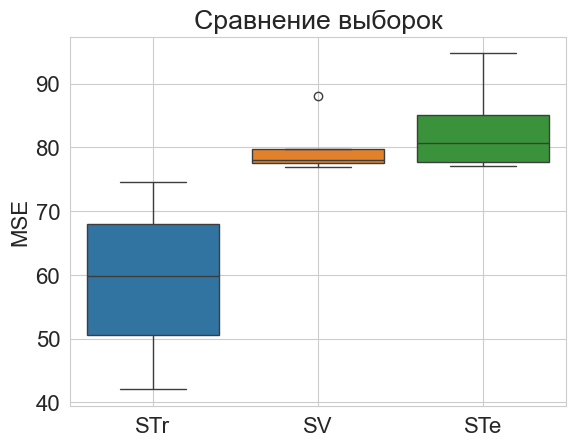

In [ ]:
results_df = pd.DataFrame({
    'STr': sgd_train_results,
    'SV': sgd_val_results,
    'STe': sgd_test_results
})

sns.boxplot(data=results_df)
plt.title('Сравнение выборок')
plt.ylabel('MSE')
plt.grid(True)
plt.show()

This looks like a disaster: the model clearly overfits. On train the values are scattered all over the place, sometimes below 50, while on val and test they are much higher.<br>
I also ran it with Adam, and Adam just shot through the roof <br>
![image info](output.png)

**Task 2.3 (1 point).** As you should have noticed, the more complex model overfits more. Let's add regularization to fight overfitting. Add a dropout layer ([`nn.Dropout`](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html#torch.nn.Dropout)) with $p=0.2$ after every linear layer except the last one. You can read about dropout in this [blog post](https://medium.com/@amarbudhiraja/https-medium-com-amarbudhiraja-learning-less-to-learn-better-dropout-in-deep-machine-learning-74334da4bfc5) or in the original [paper](https://jmlr.org/papers/volume15/srivastava14a/srivastava14a.pdf)

Describe the results.

In [ ]:
import torch.nn as nn

class complex_cnn_with_dropout(nn.Module):
    def __init__(self, input_size, hidden_size, dropout_p=0.2):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.dropout1 = nn.Dropout(p=dropout_p)
        self.fc2 = nn.Linear(hidden_size, hidden_size // 2)
        self.dropout2 = nn.Dropout(p=dropout_p)
        self.fc3 = nn.Linear(hidden_size // 2, hidden_size // 4)
        self.dropout3 = nn.Dropout(p=dropout_p)
        self.fc4 = nn.Linear(hidden_size // 4, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout1(x)

        x = self.fc2(x)
        x = self.relu(x)
        x = self.dropout2(x)

        x = self.fc3(x)
        x = self.relu(x)
        x = self.dropout3(x)

        x = self.fc4(x)
        x = self.sigmoid(x)
        return x

In [ ]:
model = complex_cnn_with_dropout(input_size, hidden_size)
print("SGDM: ")
sgd_train_results, sgd_val_results, sgd_test_results = run_model(5, model, 'sgdm')

SGDM: 
Test MSE: 77.84
Validation MSE: 79.49
Trains MSE: 80.84
Test MSE: 76.14
Validation MSE: 77.44
Trains MSE: 77.93
Test MSE: 75.46
Validation MSE: 76.32
Trains MSE: 75.96
Test MSE: 74.92
Validation MSE: 75.45
Trains MSE: 74.33
Test MSE: 74.83
Validation MSE: 74.85
Trains MSE: 72.52


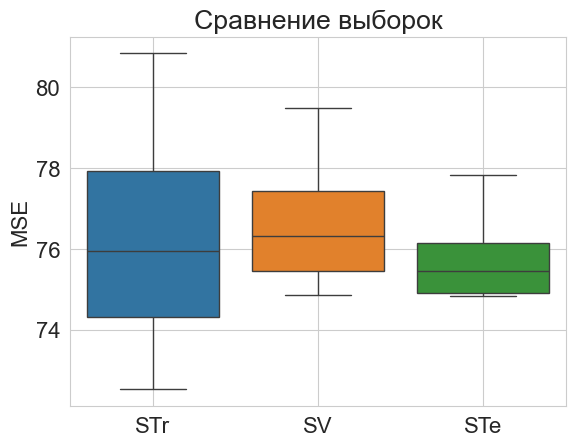

In [ ]:
results_df = pd.DataFrame({
    'STr': sgd_train_results,
    'SV': sgd_val_results,
    'STe': sgd_test_results
})

sns.boxplot(data=results_df)
plt.title('Сравнение выборок')
plt.ylabel('MSE')
plt.grid(True)
plt.show()

With dropout it got much better: val & test are on the same level as train, and they are lower than last time. A complete success!

**Task 2.4 (1.5 points).** Now that we have chosen the network architecture, it is time for the routine work of a DL engineer — hyperparameter search. Find the optimal lr by validation MSE (on a logarithmic grid; 3–4 values are enough). You can use `verbose=False` in `train_and_validate`.

Also find the optimal weight decay for this lr. Weight decay is the neural-network analogue of L2 regularization. You can read about it, for example, [here](https://paperswithcode.com/method/weight-decay). In PyTorch it is set with the optimizer's `weight_decay` parameter. Find the optimal weight decay on a logarithmic grid (typical values are in the range $[10^{-6}, 10^{-3}]$, but do not forget to include zero in the grid).

Plot train and validation MSE against the parameter values. Comment on the resulting dependencies.

In [ ]:
lrs = [1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2]
train_mse_list = []
val_mse_list = []

def custom_mse(predictions_normalized, true_values_normalized):
    predictions = denormalize(predictions_normalized.detach().numpy())
    true_values = denormalize(true_values_normalized.detach().numpy())
    return mean_squared_error(true_values, predictions)

for lr in lrs:
    model2 = complex_cnn_with_dropout(input_size=X_train.shape[1], hidden_size=512)
    optimizer = torch.optim.SGD(model2.parameters(), lr=lr, momentum=0.9)
    criterion = nn.MSELoss()
    metric = custom_mse

    train_mse, val_mse = train_and_validate(
        model2, optimizer, criterion, metric,
        train_loader, val_loader,
        num_epochs=10, verbose=False
    )

    train_mse_list.append(train_mse)
    val_mse_list.append(val_mse)

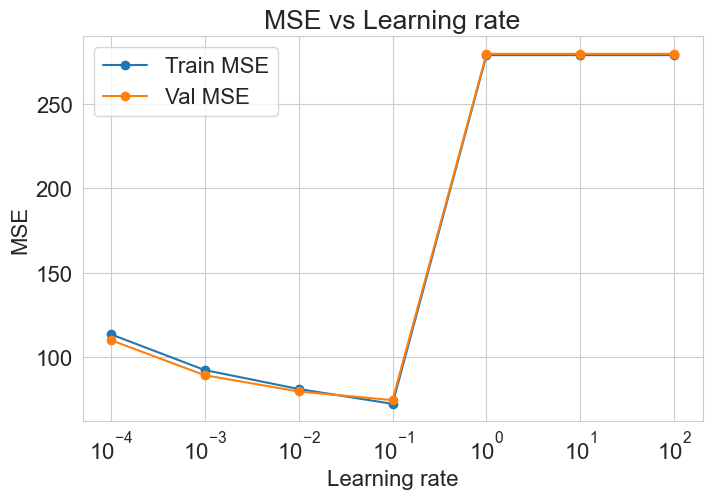

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(lrs, train_mse_list, marker='o', label='Train MSE')
plt.plot(lrs, val_mse_list, marker='o', label='Val MSE')
plt.xscale('log')
plt.xlabel("Learning rate")
plt.ylabel("MSE")
plt.title("MSE vs Learning rate")
plt.legend()
plt.grid(True)
plt.show()

For lr > 1e-2 the validation MSE becomes worse than the training MSE, i.e. the model starts to overfit.

In [ ]:
weight_decays = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
train_mse_wd, val_mse_wd = [], []

for wd in weight_decays:
    model3 = complex_cnn_with_dropout(input_size=X_train.shape[1], hidden_size=512)
    optimizer = torch.optim.SGD(model3.parameters(), lr=1e-2, momentum=0.9, weight_decay=wd)
    criterion = nn.MSELoss()
    metric = custom_mse

    train_mse, val_mse = train_and_validate(
        model3, optimizer, criterion, metric,
        train_loader, val_loader,
        num_epochs=10, verbose=False
    )

    train_mse_wd.append(train_mse)
    val_mse_wd.append(val_mse)

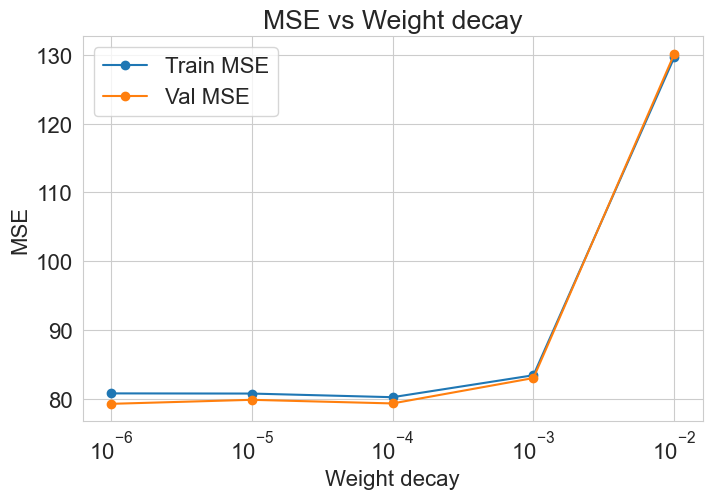

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(weight_decays, train_mse_wd, marker='o', label='Train MSE')
plt.plot(weight_decays, val_mse_wd, marker='o', label='Val MSE')
plt.xscale('log')
plt.xlabel("Weight decay")
plt.ylabel("MSE")
plt.title("MSE vs Weight decay")
plt.legend()
plt.grid(True)
plt.show()

For wd > 1e-4 the MSE starts to increase, and there is a dip at 1e-4, so it makes sense to use that value.

As you may have noticed, another routine part of a DL engineer's job is the tedious wait for models to train.

**Task 2.5 (0.5 points).** We have run many experiments and found the optimal architecture and hyperparameters. It is time to train the model on the full training set, measure the quality on the test set and compare it with the baselines. Do it.

In [ ]:
from sklearn.preprocessing import StandardScaler

y_train_norm = normalize(y_train)
y_val_norm = normalize(y_val)
y_train_tensor = torch.tensor(y_train_norm, dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val_norm, dtype=torch.float32).reshape(-1, 1)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

X_test_scaled = scaler.transform(X_test)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_test_normaliszed = normalize(y_test)
y_test_tensor = torch.tensor(y_test_normaliszed, dtype=torch.float32)

In [ ]:
model4 = complex_cnn_with_dropout(
    input_size=X_train.shape[1],
    hidden_size=512,
    dropout_p=0.2
)

optimizer = torch.optim.SGD(
    model4.parameters(),
    lr=1e-2,
    weight_decay=1e-4,
    momentum=0.9
)

criterion = nn.MSELoss()
metric = custom_mse

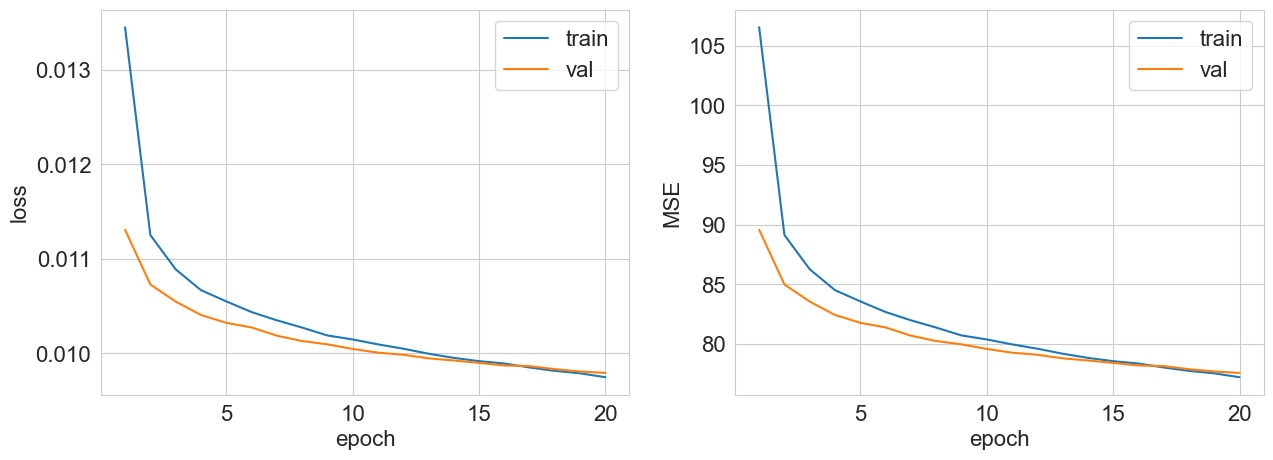

Validation MSE: 77.560


In [ ]:
train_mse, val_mse = train_and_validate(
    model4, optimizer, criterion, metric,
    train_loader, val_loader,
    num_epochs=20, verbose=True
)

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# среднее значение по y_train
y_pred_const = np.full_like(y_test, y_train.mean(), dtype=np.float64)
# MSE для константного прогноза
mse_const = mean_squared_error(y_test, y_pred_const)
print(f"MSE для наилучшего константного прогноза: {mse_const:.2f}")

# инициализация и обучение модели
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)

# предсказания и MSE
y_pred_ridge = ridge.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
print(f"MSE Ridge-регрессии: {mse_ridge:.2f}")

model.eval()
with torch.no_grad():
    y_pred = model(X_test_tensor).view(-1, 1)
test_mse = custom_mse(y_pred, y_test_tensor)
print(f"MSE on Neural Network: {test_mse:.2f}")

MSE для наилучшего константного прогноза: 117.63
MSE Ridge-регрессии: 89.76
MSE on Neural Network: 74.83


Done.